In [1]:
import numpy as np
import cupy as cp
import scipy
from tqdm import tqdm
import multiprocessing as mp
import os
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from ipywidgets import interact, IntSlider, Play, jslink, VBox
from IPython.display import display
from dataclasses import dataclass
import plane_wave
import cupyx
from cupyx.scipy import signal
import matplotlib.animation as animation

/home/nbyrnes/.conda/envs/memory_effect/lib/python3.12/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


In [2]:
def czt2(
    input: np.array,
    x_min: float | None = None,
    x_max: float | None = None,
    y_min: float | None = None,
    y_max: float | None = None,
    Nx: float = 512,
    Nk: float = 512,
    mode: str = "FT",
    kscale: float  = 1.0,
) -> np.array:

    xp = cp.get_array_module(input)
    czt = scipy.signal.czt if xp == np else cupyx.scipy.signal.czt

    if x_min == None:
        x_min = -10 * (2 * xp.pi / kscale)
    if y_min == None:
        y_min = -10 * (2 * xp.pi / kscale)
    if x_max == None:
        x_max = 10 * (2 * xp.pi / kscale)
    if y_max == None:
        y_max = 10 * (2 * xp.pi / kscale)

    x0 = xp.linspace(x_min, x_max, Nx)
    y0 = xp.linspace(y_min, y_max, Nx)
    # k range
    kmin = -kscale
    kmax = kscale
    # samples in k space

    k0 = xp.linspace(kmin, kmax, Nk)

    a = -1
    ak = 1

    dx = abs(x0[2] - x0[1])
    dy = abs(y0[2] - y0[1])
    dkx = abs(k0[2] - k0[1])

    Wkx = xp.exp(-1j * ak * dx * dkx)
    Wx = xp.exp(-1j * a * dx * dkx)  # used in IFT
    Akx = xp.exp(1j * ak * kmin * dx)
    Aky = xp.exp(1j * ak * kmin * dy)
    Ax = xp.exp(1j * a * x_min * dkx)  # used in IFT
    Ay = xp.exp(1j * a * y_min * dkx)  # used in IFT
    # these factors account for the shift of origin using shift theorem
    pkx = xp.exp(-ak * 1j * (x_min) * k0)
    pky = xp.exp(-ak * 1j * (y_min) * k0)
    px = xp.exp(-a * 1j * (kmin) * x0)
    if mode == "FT":
        row_czt = xp.array(
            [dx * pkx * czt(row, Nk, Wkx, Akx) for row in input]
        )  # row-wise czt
        ft = xp.array(
            [dy * pky * czt(col, Nk, Wkx, Aky) for col in row_czt.T]
        ).T  # column-wise czt
        return ft
    elif mode == "IFT":
        row_czt = xp.array(
            [
                (1 / (2 * np.pi)) * dkx * px * czt(row, Nx, Wx, Ax)
                for row in input
            ]
        )
        ift = xp.array(
            [
                (1 / (2 * np.pi)) * dkx * px * czt(col, Nx, Wx, Ay)
                for col in row_czt.T
            ]
        ).T
        return ift

In [3]:
# If true, show speckles at a few different thicknesses to get an idea of suitable window sizes
calibrate = False

In [4]:
# Simulation parameters
wavelength = 500e-9
use_cupy = True
xp = cp if use_cupy else np
seed = 0

# Scattering medium
# All dimensions are in units of vacuum wavelength
medium_x_extent = 1000
medium_y_extent = 1000
medium_z_extent = 10
medium_num_particles = 1000
medium_parameters = plane_wave.MediumParameters(
    medium_x_extent, medium_y_extent, medium_z_extent, medium_num_particles
)

# Parameters for measurement plane
measurement_plane_dz = 5
measurement_plane_z_transmission = (medium_z_extent / 2) + measurement_plane_dz
measurement_plane_z_reflection = -measurement_plane_z_transmission

# Nyquist rates (in wavelengths)
measurement_x_extent = 1000
measurement_y_extent = measurement_x_extent

nyquist_number_x = int(measurement_x_extent / 0.5)
nyquist_number_y = int(measurement_y_extent / 0.5)

factor = 1
measurement_number_x = int(nyquist_number_x * factor)
measurement_number_y = measurement_number_x

# k-space resolution (in normalized k units)
measurement_number_kx = measurement_number_x
measurement_number_ky = measurement_number_kx

measurement_plane_parameters_transmission = (
    plane_wave.MeasurementPlaneParameters(
        measurement_x_extent,
        measurement_y_extent,
        measurement_plane_z_transmission,
        measurement_number_x,
        measurement_number_y,
    )
)
measurement_plane_parameters_reflection = (
    plane_wave.MeasurementPlaneParameters(
        measurement_x_extent,
        measurement_y_extent,
        measurement_plane_z_reflection,
        measurement_number_x,
        measurement_number_y,
    )
)
dk = 2 / measurement_number_kx

sp_t = plane_wave.SimulationParameters(
    wavelength,
    use_cupy,
    medium_parameters,
    measurement_plane_parameters_transmission,
    seed,
)
sp_r = plane_wave.SimulationParameters(
    wavelength,
    use_cupy,
    medium_parameters,
    measurement_plane_parameters_reflection,
    seed,
)

x_particles, y_particles, z_particles = plane_wave.get_particle_locations(sp_t)

In [5]:
# Get the mean free path
k = 2 * np.pi / wavelength
medium_volume = (
    medium_x_extent * medium_y_extent * medium_z_extent * wavelength**3
)
number_density = medium_num_particles / medium_x_extent * medium_volume
cross_section = 4 * np.pi / k**2
mfp = 1/(number_density*cross_section)
mfp_wavelength = mfp / wavelength

print(mfp_wavelength)

2.0106192982974682e+31


In [6]:
wavelength**3

1.2499999999999998e-19

In [7]:
print( -measurement_x_extent / 2)
print(measurement_plane_parameters_transmission.x_lims(wavelength)[0])

-500.0
-0.00025


In [8]:
if calibrate:

    x_min, x_max = measurement_plane_parameters_transmission.x_lims(wavelength)
    y_min, y_max = measurement_plane_parameters_transmission.y_lims(wavelength)

    kx0 = 0.0
    ky0 = 0.0
    kz0 = np.sqrt(1 - kx0**2 - ky0**2)

    k0 = np.array([kx0, ky0, kz0])

    print("Calculating incdient field...")
    incident_field = plane_wave.get_incident_field(k0, sp_t).get()
    print("Calculating transmitted field...")
    scattered_field_t = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, k0, sp_t
    ).get()
    print("Calculating reflected field...")
    scattered_field_r = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, k0, sp_r
    ).get()

    print("Getting incident angular spectrum...")
    incident_field_angular_spectrum = czt2(
        x_min=x_min,
        x_max=x_max,
        y_min=y_min,
        y_max=y_max,
        Nx=measurement_number_x,
        Nk=measurement_number_kx,
        input=incident_field,
        kscale=sp_t.wavenumber,
    )
    print("Getting transmitted angular spectrum...")
    scattered_field_t_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_t,
            kscale=sp_t.wavenumber,
        )
    print("Getting reflected angular spectrum...")
    scattered_field_r_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_r,
            kscale=sp_r.wavenumber,
        )

In [9]:
if calibrate:
    fig, ax = plt.subplots(2, 3, figsize=(10, 8))

    # Real-space limits
    x_min, x_max = measurement_plane_parameters_transmission.x_lims(wavelength)
    y_min, y_max = measurement_plane_parameters_transmission.y_lims(wavelength)

    # Normalized k-space limits
    kx_min, kx_max = -1, 1
    ky_min, ky_max = -1, 1

    # -----------------------------------------------------------------------------
    # Real space fields
    # ---------------------------------------------------------------------------
    # 0,0: Incident field in real space
    ax[0, 0].imshow(
        np.abs(incident_field),
        extent=[x_min, x_max, y_min, y_max],
        origin="lower",
        cmap="viridis",
    )
    ax[0, 0].set_title("|E_i|")
    ax[0, 0].set_xlabel("x [λ]")
    ax[0, 0].set_ylabel("y [λ]")

    # 0,1: Transmitrted field in real space
    ax[0, 1].imshow(
        np.abs(scattered_field_t),
        extent=[x_min, x_max, y_min, y_max],
        origin="lower",
        cmap="viridis",
    )
    ax[0, 1].set_title("|E_t|")
    ax[0, 1].set_xlabel("x [λ]")
    ax[0, 1].set_ylabel("y [λ]")

    # 0,2: Reflected field in real space
    ax[0, 2].imshow(
        np.abs(scattered_field_r),
        extent=[x_min, x_max, y_min, y_max],
        origin="lower",
        cmap="viridis",
    )
    ax[0, 2].set_title("|E_r|")
    ax[0, 2].set_xlabel("x [λ]")
    ax[0, 2].set_ylabel("y [λ]")


    # 1,0: Incident field in Fourier space
    ax[1, 0].imshow(
        np.abs(incident_field_angular_spectrum),
        extent=[kx_min, kx_max, ky_min, ky_max],
        origin="lower",
        cmap="viridis",
    )
    ax[1, 0].set_title("|FFT(E_i)|")
    ax[1, 0].set_xlabel("kx/k")
    ax[1, 0].set_ylabel("ky/k")

    # 1,0: Incident field in Fourier space
    ax[1, 1].imshow(
        np.abs(scattered_field_t_angular_spectrum),
        extent=[kx_min, kx_max, ky_min, ky_max],
        origin="lower",
        cmap="viridis",
    )
    ax[1, 1].set_title("|FFT(E_t)|")
    ax[1, 1].set_xlabel("kx/k")
    ax[1, 1].set_ylabel("ky/k")

    # 1,0: Incident field in Fourier space
    ax[1, 2].imshow(
        np.abs(scattered_field_r_angular_spectrum),
        extent=[kx_min, kx_max, ky_min, ky_max],
        origin="lower",
        cmap="viridis",
    )
    ax[1, 2].set_title("|FFT(E_r)|")
    ax[1, 2].set_xlabel("kx/k")
    ax[1, 2].set_ylabel("ky/k")


    plt.tight_layout()
    plt.show()

In [10]:
if calibrate:
    ratio_lower = 0.35
    ratio_upper = 0.40
    low_index = int(measurement_number_kx * ratio_lower)
    high_index = int(measurement_number_kx * ratio_upper)
    # Real-space limits
    x_min, x_max = -measurement_x_extent / 2, measurement_x_extent / 2
    y_min, y_max = -measurement_y_extent / 2, measurement_y_extent / 2

    # Normalized k-space limits
    kx_min, kx_max = -1, 1
    ky_min, ky_max = -1, 1
    wavevector_index = 0
    fig, ax = plt.subplots(figsize=(12,12))
    ax.imshow(
        np.abs(scattered_field_t)[
            low_index:high_index, low_index:high_index
        ],
        extent=[kx_min, kx_max, ky_min, ky_max],
        origin="lower",
        cmap="viridis",
    )

In [11]:
if calibrate:
    raise ValueError("Calibrate mode active")

#### Experiment 1: Tilting
k_i and k_u are fixed

In [12]:
kx_coords = np.linspace(-1, 1, measurement_number_kx)
ky_coords = np.linspace(-1, 1, measurement_number_kx)
KX, KY = np.meshgrid(kx_coords, ky_coords)
print(measurement_number_kx)

2000


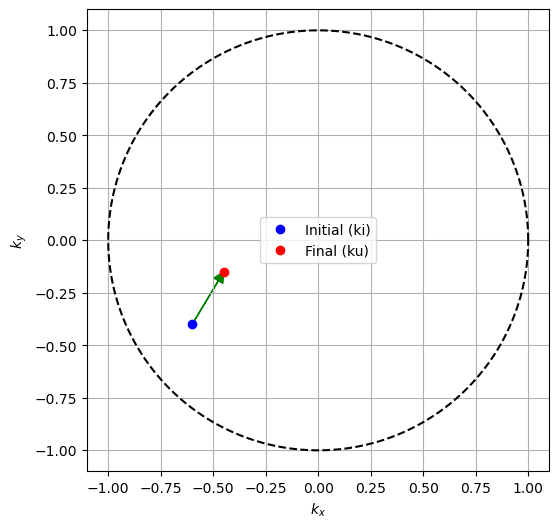

In [13]:
ki_i = 600
ki_j = 400

ku_i = 850
ku_j = 550

ki_x = KX[ki_i, ki_j]
ki_y = KY[ki_i, ki_j]
ku_x = KX[ku_i, ku_j]
ku_y = KY[ku_i, ku_j]

dkx = ku_x - ki_x
dky = ku_y - ki_y

kx = np.linspace(ki_x, ku_x, 2)
ky = np.linspace(ki_y, ku_y, 2)
kz = np.sqrt(1.0 - kx**2 - ky**2)
incident_wavevectors = np.stack([kx, ky, kz], axis=1)

# Plot
fig, ax = plt.subplots(figsize=(6,6))

# Plot unit circle
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), 'k--')

# Plot points
ax.plot(ki_x, ki_y, 'bo', label='Initial (ki)')
ax.plot(ku_x, ku_y, 'ro', label='Final (ku)')

# Draw arrow from initial to final
ax.arrow(ki_x, ki_y, ku_x - ki_x, ku_y - ki_y,
         head_width=0.05, head_length=0.05, fc='green', ec='green', length_includes_head=True)

# Labels and styling
ax.set_xlabel('$k_x$')
ax.set_ylabel('$k_y$')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(True)
ax.legend()
plt.show()


In [14]:
print(dkx, dky)

0.15007503751875928 0.25012506253126565


In [15]:
print(ki_x, ki_y)
print(ku_x, ku_y)

-0.599799899949975 -0.39969984992496255
-0.4497248624312157 -0.1495747873936969


In [16]:
x_min, x_max = measurement_plane_parameters_transmission.x_lims(wavelength)
y_min, y_max = measurement_plane_parameters_transmission.y_lims(wavelength)

transmitted_fields = []
reflected_fields = []

transmitted_angular_spectra = []
reflected_angular_spectra = []

for incident_wavevector in tqdm(incident_wavevectors):
    print("Calculating transmitted field...")
    scattered_field_t = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_t
    ).get()
    transmitted_fields.append(scattered_field_t)

    print("Calculating reflected field...")
    scattered_field_r = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_r
    ).get()
    reflected_fields.append(scattered_field_r)
    
    print("Getting transmitted angular spectrum...")
    scattered_field_t_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_t,
            kscale=sp_t.wavenumber,
        )    
    transmitted_angular_spectra.append(scattered_field_t_angular_spectrum)

    print("Getting reflected angular spectrum...")
    scattered_field_r_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_r,
            kscale=sp_r.wavenumber,
        )
    reflected_angular_spectra.append(scattered_field_r_angular_spectrum)

  0%|          | 0/2 [00:00<?, ?it/s]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


 50%|█████     | 1/2 [00:11<00:11, 11.22s/it]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


100%|██████████| 2/2 [00:22<00:00, 11.13s/it]


In [17]:
print(scattered_field_t.shape)
print(scattered_field_t_angular_spectrum.shape)

(2000, 2000)
(2000, 2000)


In [18]:
# Assume these are defined
untilted = transmitted_angular_spectra[0]
tilted = transmitted_angular_spectra[1]


shift_x = ku_j - ki_j
shift_y = ku_i - ki_i

H, W = untilted.shape

# X direction
if shift_x > 0:
    untilted_crop = untilted[:, :-shift_x]
    tilted_crop   = tilted[:, shift_x:]
    KX_crop = KX[:, :-shift_x]
    KY_crop = KY[:, :-shift_x]

elif shift_x < 0:
    untilted_crop = untilted[:, -shift_x:]
    tilted_crop   = tilted[:, :shift_x]
    KX_crop = KX[:, -shift_x:]
    KY_crop = KY[:, -shift_x:]

else:
    untilted_crop = untilted
    tilted_crop   = tilted
    KX_crop = KX
    KY_crop = KY

# Y direction
if shift_y > 0:
    untilted_crop = untilted_crop[:-shift_y, :]
    tilted_crop   = tilted_crop[shift_y:, :]
    KX_crop = KX_crop[:-shift_y, :]
    KY_crop = KY_crop[:-shift_y, :]

elif shift_y < 0:
    untilted_crop = untilted_crop[-shift_y:, :]
    tilted_crop   = tilted_crop[:shift_y, :]
    KX_crop = KX_crop[-shift_y:, :]
    KY_crop = KY_crop[-shift_y:, :]

KZ_crop = np.sqrt(1.0 - KX_crop**2 - KY_crop**2)

/tmp/ipykernel_592468/2586154735.py:43: RuntimeWarning: invalid value encountered in sqrt
  KZ_crop = np.sqrt(1.0 - KX_crop**2 - KY_crop**2)


In [19]:
print(untilted_crop.shape)

(1750, 1850)


In [20]:
print(shift_x)
print(shift_y)

150
250


(-1.725440981217655e-12-1.878410162976906e-12j)


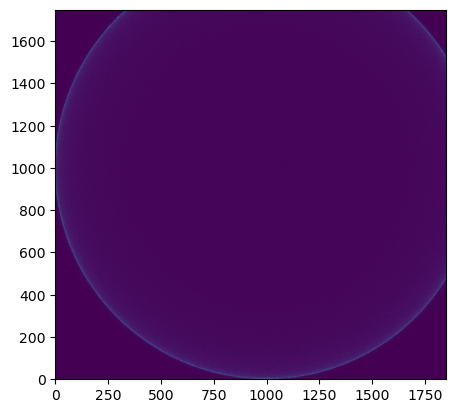

In [21]:
plt.imshow(np.abs(untilted_crop),origin="lower")
print(untilted[500,500])

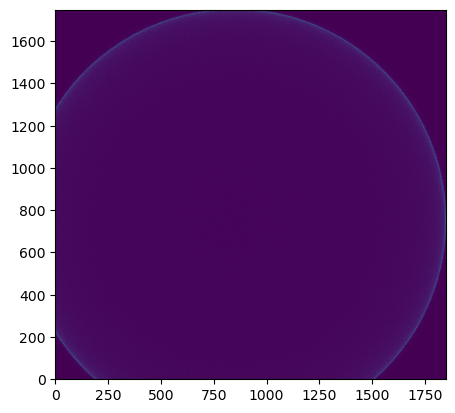

In [22]:
plt.imshow(np.abs(tilted_crop),origin="lower")


In [23]:
window_size =3 # choose an odd number so the center is clear
half_w = window_size // 2

rows, cols = untilted_crop.shape

# Pad the frame to handle edges
padded_first = np.pad(untilted_crop, half_w, mode="constant", constant_values=0)
padded_second = np.pad(
    tilted_crop, half_w, mode="constant", constant_values=0
)

local_corr = np.zeros_like(untilted_crop)

for i in tqdm(range(rows)):
    for j in range(cols):
        patch1 = np.abs(padded_first[i : i + window_size, j : j + window_size])**2
        patch2 = np.abs(padded_second[i : i + window_size, j : j + window_size])**2
        local_corr[i, j] = np.abs(np.sum(patch1 * np.conj(patch2))) / (
            np.sqrt(np.sum(np.abs(patch1) ** 2))
            * np.sqrt(np.sum(np.abs(patch2) ** 2))
        )

  0%|          | 0/1750 [00:00<?, ?it/s]

100%|██████████| 1750/1750 [00:36<00:00, 47.42it/s]


(1750, 1850)


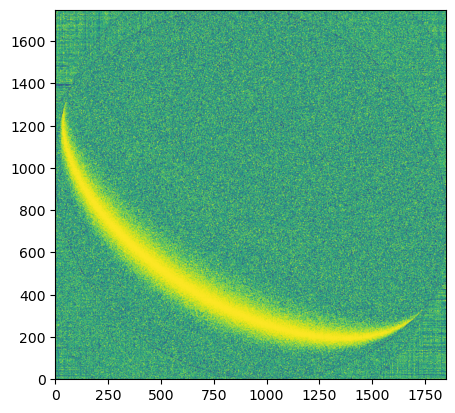

In [24]:
plt.imshow(np.abs(local_corr),origin='lower')
print(local_corr.shape)

In [25]:
kx_min, kx_max = KX_crop.min(), KX_crop.max()
ky_min, ky_max = KY_crop.min(), KY_crop.max()
Nx, Ny = 2000, 2000   # or whatever you want

kx = np.linspace(kx_min, kx_max, Nx)
ky = np.linspace(ky_min, ky_max, Ny)
KX_new, KY_new = np.meshgrid(kx, ky)

def f(KX, KY):
    return (
        np.sqrt(1 - ki_x**2 - ki_y**2)
        - np.sqrt(1 - ku_x**2 - ku_y**2)
        - np.sqrt(1 - KX**2 - KY**2)
        + np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)
    )
def f_r(KX, KY):
    return (
        np.sqrt(1 - ki_x**2 - ki_y**2)
        - np.sqrt(1 - ku_x**2 - ku_y**2)
        + np.sqrt(1 - KX**2 - KY**2)
        - np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)
    )



F = f(KX_new, KY_new)
F_r = f_r(KX_new, KY_new)
# tol = 1e-5
# theory_mask = (
#     np.abs(np.sqrt(1 - ki_x**2 - ki_y**2)
#     - np.sqrt(1 - ku_x**2 - ku_y**2)
#     - np.sqrt(1 - KX_new**2 - KY_new**2)
#     + np.sqrt(1 - (KX_new + dkx) ** 2 - (KY_new + dky) ** 2))
#     <= tol
# )

# theory_mask_r = (
#     np.abs(np.sqrt(1 - ki_x**2 - ki_y**2)
#     - np.sqrt(1 - ku_x**2 - ku_y**2)
#     + np.sqrt(1 - KX_new**2 - KY_new**2)
#     - np.sqrt(1 - (KX_new + dkx) ** 2 - (KY_new + dky) ** 2))
#     <= tol
# )

/tmp/ipykernel_592468/1658429556.py:13: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - KX**2 - KY**2)
/tmp/ipykernel_592468/1658429556.py:14: RuntimeWarning: invalid value encountered in sqrt
  + np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)
/tmp/ipykernel_592468/1658429556.py:20: RuntimeWarning: invalid value encountered in sqrt
  + np.sqrt(1 - KX**2 - KY**2)
/tmp/ipykernel_592468/1658429556.py:21: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)


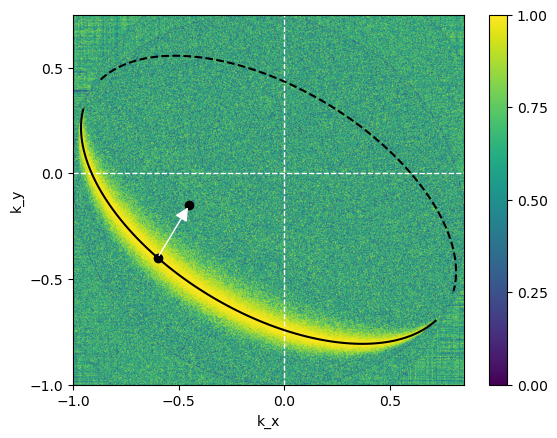

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

# Base image
im = ax.imshow(
    np.abs(local_corr),
    origin="lower",
    extent=[KX_crop.min(), KX_crop.max(), KY_crop.min(), KY_crop.max()],
    vmin=0,
    vmax=1,
    cmap="viridis",
)

# Overlay contour of mask
lw = 1.5
ax.contour(KX_new, KY_new, F, levels=[0], colors="black", linewidths=lw,zorder=1)
ax.contour(
    KX_new,
    KY_new,
    F_r,
    levels=[0],
    colors="black",
    linestyles="--",
    linewidths=lw,
    zorder=1
)

# ax.contour(KX_new, KY_new, theory_mask_r.astype(float), levels=[0.5], colors='black', linewidths=2, linestyles="--")

# Plot ki and ku points
mst = "o"
ms = 6
ax.plot(ki_x, ki_y, mst, color="black", markersize=ms, label="ki",zorder=2)
ax.plot(ku_x, ku_y, mst, color="black", markersize=ms, label="ki",zorder=2)

# Draw arrow from ki → ku
ax.annotate(
    "",
    xy=(ku_x, ku_y),
    xytext=(ki_x, ki_y),
    arrowprops=dict(
        arrowstyle="-|>", color="white", linewidth=1, mutation_scale=20
    ),
    zorder=3,
)
ax.axhline(0, color="white", linestyle="--", linewidth=1, zorder=0)
ax.axvline(0, color="white", linestyle="--", linewidth=1, zorder=0)

# # Plot circular boundary
# t = np.linspace(0, 2 * np.pi, 1000)
# x = np.cos(t)
# y = np.sin(t)
# ax.plot(x, y, color="white", linestyle="--", linewidth=1)

cbar = fig.colorbar(im, ax=ax)
ax.set_xlabel("k_x")
ax.set_ylabel("k_y")
# ax.legend()
from matplotlib.ticker import MultipleLocator

ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
cbar.ax.yaxis.set_major_locator(MultipleLocator(0.25))
plt.savefig("transmission_band_final.svg",format="svg")
plt.show()


#### Experiment 2: tt' loop correlations
k_i and k_u are fixed

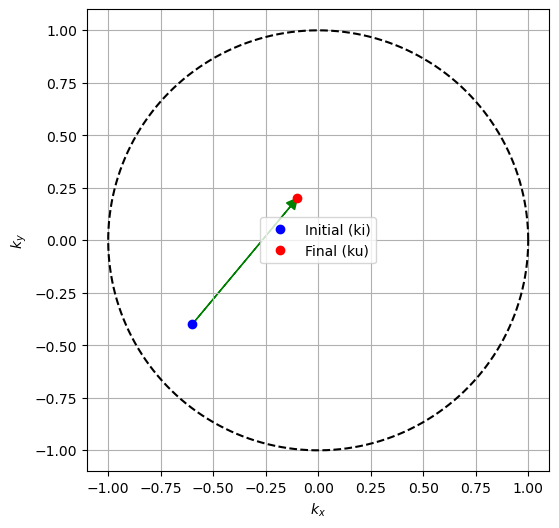

In [27]:
ki_i = 600
ki_j = 400

ku_i = 1200
ku_j = 900

ki_x = KX[ki_i, ki_j]
ki_y = KY[ki_i, ki_j]
ku_x = KX[ku_i, ku_j]
ku_y = KY[ku_i, ku_j]

dkx = ku_x - ki_x
dky = ku_y - ki_y

kx = np.linspace(ki_x, ku_x, 2)
ky = np.linspace(ki_y, ku_y, 2)
kz = np.sqrt(1.0 - kx**2 - ky**2)
incident_wavevectors = np.stack([kx, ky, kz], axis=1)

# Plot
fig, ax = plt.subplots(figsize=(6,6))

# Plot unit circle
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), 'k--')

# Plot points
ax.plot(ki_x, ki_y, 'bo', label='Initial (ki)')
ax.plot(ku_x, ku_y, 'ro', label='Final (ku)')

# Draw arrow from initial to final
ax.arrow(ki_x, ki_y, ku_x - ki_x, ku_y - ki_y,
         head_width=0.05, head_length=0.05, fc='green', ec='green', length_includes_head=True)

# Labels and styling
ax.set_xlabel('$k_x$')
ax.set_ylabel('$k_y$')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(True)
ax.legend()
plt.show()


In [28]:
# Make the second incident wave propagate in the backwards direction
incident_wavevectors[1][2] = -incident_wavevectors[1][2]
print(incident_wavevectors)

[[-0.5997999  -0.39969985  0.69316673]
 [-0.09954977  0.2006003  -0.97460216]]


In [29]:
x_min, x_max = measurement_plane_parameters_transmission.x_lims(wavelength)
y_min, y_max = measurement_plane_parameters_transmission.y_lims(wavelength)

transmitted_fields = []
reflected_fields = []

transmitted_angular_spectra = []
reflected_angular_spectra = []

for incident_wavevector in tqdm(incident_wavevectors):
    print("Calculating transmitted field...")
    scattered_field_t = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_t
    ).get()
    transmitted_fields.append(scattered_field_t)

    print("Calculating reflected field...")
    scattered_field_r = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_r
    ).get()
    reflected_fields.append(scattered_field_r)
    
    print("Getting transmitted angular spectrum...")
    scattered_field_t_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_t,
            kscale=sp_t.wavenumber,
        )    
    transmitted_angular_spectra.append(scattered_field_t_angular_spectrum)

    print("Getting reflected angular spectrum...")
    scattered_field_r_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_r,
            kscale=sp_r.wavenumber,
        )
    reflected_angular_spectra.append(scattered_field_r_angular_spectrum)

  0%|          | 0/2 [00:00<?, ?it/s]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


 50%|█████     | 1/2 [00:10<00:10, 10.90s/it]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


100%|██████████| 2/2 [00:21<00:00, 10.91s/it]


In [30]:
# Assume these are defined
untilted = transmitted_angular_spectra[0]
tilted = reflected_angular_spectra[1]

Nky, Nkx = untilted.shape

kx_coords = np.linspace(-1, 1, Nkx)
ky_coords = np.linspace(-1, 1, Nky)
KX, KY = np.meshgrid(kx_coords, ky_coords)

shift_x = ku_j - ki_j
shift_y = ku_i - ki_i

H, W = untilted.shape

# X direction
if shift_x > 0:
    untilted_crop = untilted[:, :-shift_x]
    tilted_crop   = tilted[:, shift_x:]
    KX_crop = KX[:, :-shift_x]
    KY_crop = KY[:, :-shift_x]

elif shift_x < 0:
    untilted_crop = untilted[:, -shift_x:]
    tilted_crop   = tilted[:, :shift_x]
    KX_crop = KX[:, -shift_x:]
    KY_crop = KY[:, -shift_x:]

else:
    untilted_crop = untilted
    tilted_crop   = tilted
    KX_crop = KX
    KY_crop = KY

# Y direction
if shift_y > 0:
    untilted_crop = untilted_crop[:-shift_y, :]
    tilted_crop   = tilted_crop[shift_y:, :]
    KX_crop = KX_crop[:-shift_y, :]
    KY_crop = KY_crop[:-shift_y, :]

elif shift_y < 0:
    untilted_crop = untilted_crop[-shift_y:, :]
    tilted_crop   = tilted_crop[:shift_y, :]
    KX_crop = KX_crop[-shift_y:, :]
    KY_crop = KY_crop[-shift_y:, :]

KZ_crop = np.sqrt(1.0 - KX_crop**2 - KY_crop**2)



/tmp/ipykernel_592468/250417335.py:48: RuntimeWarning: invalid value encountered in sqrt
  KZ_crop = np.sqrt(1.0 - KX_crop**2 - KY_crop**2)


In [31]:
window_size =3 # choose an odd number so the center is clear
half_w = window_size // 2

rows, cols = untilted_crop.shape

# Pad the frame to handle edges
padded_first = np.pad(untilted_crop, half_w, mode="constant", constant_values=0)
padded_second = np.pad(
    tilted_crop, half_w, mode="constant", constant_values=0
)

local_corr = np.zeros_like(untilted_crop)

for i in tqdm(range(rows)):
    for j in range(cols):
        patch1 = np.abs(padded_first[i : i + window_size, j : j + window_size])**2
        patch2 = np.abs(padded_second[i : i + window_size, j : j + window_size])**2
        local_corr[i, j] = np.sum(patch1 * patch2) / (np.sqrt(np.sum(patch1**2) * np.sum(patch2**2)))

  0%|          | 0/1400 [00:00<?, ?it/s]

100%|██████████| 1400/1400 [00:21<00:00, 66.67it/s]


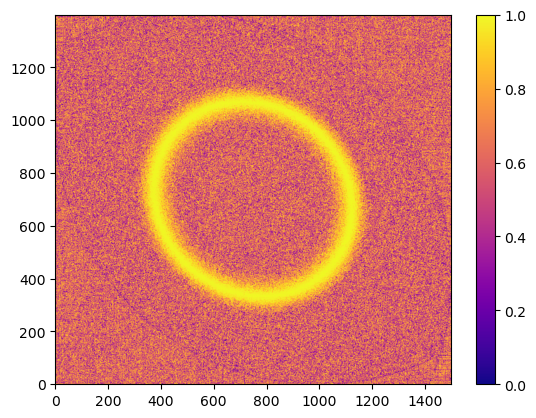

In [32]:
plt.imshow(np.abs(local_corr),origin='lower',vmin=0,vmax=1,cmap="plasma")
plt.colorbar()

In [33]:
kx_min, kx_max = KX_crop.min(), KX_crop.max()
ky_min, ky_max = KY_crop.min(), KY_crop.max()
Nx, Ny = 2000, 2000   # or whatever you want

kx = np.linspace(kx_min, kx_max, Nx)
ky = np.linspace(ky_min, ky_max, Ny)
KX_new, KY_new = np.meshgrid(kx, ky)

def f(KX, KY):
    return (
        np.sqrt(1 - ki_x**2 - ki_y**2)
        + np.sqrt(1 - ku_x**2 - ku_y**2)
        - np.sqrt(1 - KX**2 - KY**2)
        - np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)
    )
F = f(KX_new, KY_new)

/tmp/ipykernel_592468/1792355818.py:13: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - KX**2 - KY**2)
/tmp/ipykernel_592468/1792355818.py:14: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - (KX + dkx)**2 - (KY + dky)**2)


In [34]:
# tol = 1e-3
# theory_mask = (
#     np.abs(np.sqrt(1 - ki_x**2 - ki_y**2)
#     + np.sqrt(1 - ku_x**2 - ku_y**2)
#     - np.sqrt(1 - KX_crop**2 - KY_crop**2)
#     - np.sqrt(1 - (KX_crop + dkx) ** 2 - (KY_crop + dky) ** 2))
#     <= tol
# )

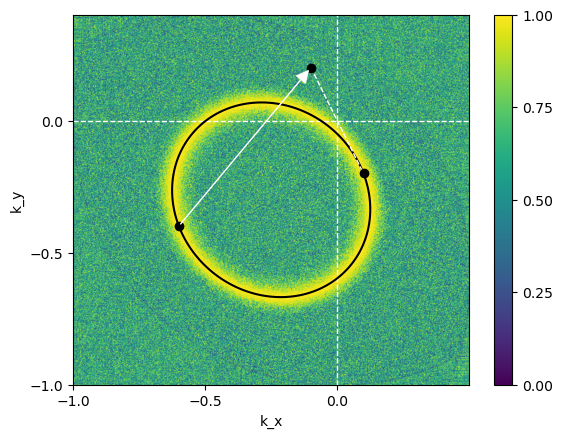

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

# Base image
im = ax.imshow(
    np.abs(local_corr),
    origin="lower",
    extent=[KX_crop.min(), KX_crop.max(), KY_crop.min(), KY_crop.max()],
    vmin=0,
    vmax=1,
    cmap="viridis",
)

# Overlay contour of mask
lw = 1.5
ax.contour(
    KX_new,
    KY_new,
    F,
    levels=[0.0],
    colors="black",
    linewidths=lw,
)
# Line joining k_j to the reciprocal point
ax.plot(
    [ku_x, -ku_x], [ku_y, -ku_y], linestyle="--", color="white", linewidth=1
)

# Plot ki and ku points
ms = 6
circle_color = "black"
ax.plot(ki_x, ki_y, marker='o', color=circle_color, ms=ms, label='ki')
ax.plot(ku_x, ku_y, marker='o', color=circle_color, ms=ms, label='ki')
ax.plot(-ku_x, -ku_y, marker='o', color="black", ms=ms, label='ki')

# Reciprocal point
# ax.plot(-ku_x, -ku_y, "x", color="black", markersize=5, label="ki")


# Draw arrow from ki → ku
ax.annotate(
    "",
    xy=(ku_x, ku_y),
    xytext=(ki_x, ki_y),
    arrowprops=dict(
        arrowstyle="-|>", color="white", linewidth=1, mutation_scale=20
    ),
    zorder=3,
)
ax.axhline(0, color="white", linestyle="--", linewidth=1,zorder=0)
ax.axvline(0, color="white", linestyle="--", linewidth=1,zorder=0)

# Plot circular boundary
# t = np.linspace(0, 2 * np.pi, 1000)
# x = np.cos(t)
# y = np.sin(t)
# ax.plot(x, y, color="white", linestyle="--", linewidth=1)

ax.set_xlim(np.min(KX_crop), np.max(KX_crop))
ax.set_ylim(np.min(KY_crop), np.max(KY_crop))
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
cbar = fig.colorbar(im, ax=ax)

cbar.ax.yaxis.set_major_locator(MultipleLocator(0.25))

ax.set_xlabel("k_x")
ax.set_ylabel("k_y")
plt.savefig("transmission_ring_final.svg",format="svg")

plt.show()

#### Experiment 3: tt loop pseudo-correlations
k_i and k_u are fixed

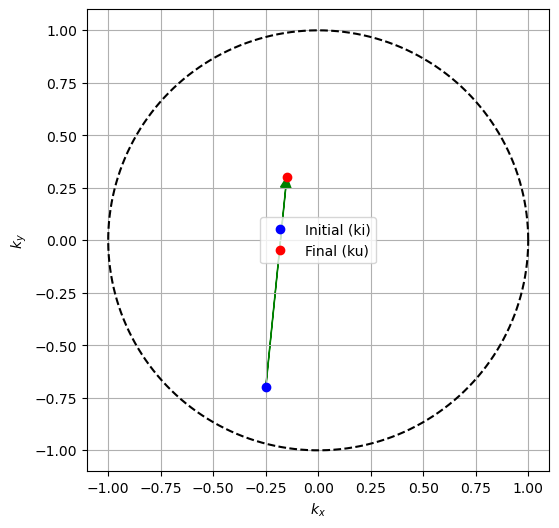

In [36]:
center_i = 800
center_j = 800
di = 500
dj = 50

ki_i = center_i - di
ki_j = center_j - dj

ku_i = center_i + di
ku_j = center_j + dj


ki_x = KX[ki_i, ki_j]
ki_y = KY[ki_i, ki_j]
ku_x = KX[ku_i, ku_j]
ku_y = KY[ku_i, ku_j]

c_x = (ki_x + ku_x) / 2
c_y = (ki_y + ku_y) / 2

dkx = ku_x - ki_x
dky = ku_y - ki_y

kx = np.linspace(ki_x, ku_x, 2)
ky = np.linspace(ki_y, ku_y, 2)
kz = np.sqrt(1.0 - kx**2 - ky**2)
incident_wavevectors = np.stack([kx, ky, kz], axis=1)

# Plot
fig, ax = plt.subplots(figsize=(6,6))

# Plot unit circle
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), 'k--')

# Plot points
ax.plot(ki_x, ki_y, 'bo', label='Initial (ki)')
ax.plot(ku_x, ku_y, 'ro', label='Final (ku)')

# Draw arrow from initial to final
ax.arrow(ki_x, ki_y, ku_x - ki_x, ku_y - ki_y,
         head_width=0.05, head_length=0.05, fc='green', ec='green', length_includes_head=True)

# Labels and styling
ax.set_xlabel('$k_x$')
ax.set_ylabel('$k_y$')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(True)
ax.legend()
plt.show()

In [37]:
print(ki_x)
print(ki_y)
print(ku_x)
print(ku_y)
print(c_x)
print(c_y)

-0.24962481240620316
-0.6998499249624812
-0.1495747873936969
0.30065032516258117
-0.19959979989995003
-0.19959979989995003


In [38]:
x_min, x_max = measurement_plane_parameters_transmission.x_lims(wavelength)
y_min, y_max = measurement_plane_parameters_transmission.y_lims(wavelength)

transmitted_fields = []
reflected_fields = []

transmitted_angular_spectra = []
reflected_angular_spectra = []

for incident_wavevector in tqdm(incident_wavevectors):
    print("Calculating transmitted field...")
    scattered_field_t = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_t
    ).get()
    transmitted_fields.append(scattered_field_t)

    print("Calculating reflected field...")
    scattered_field_r = plane_wave.get_scattered_field(
        x_particles, y_particles, z_particles, incident_wavevector, sp_r
    ).get()
    reflected_fields.append(scattered_field_r)
    
    print("Getting transmitted angular spectrum...")
    scattered_field_t_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_t,
            kscale=sp_t.wavenumber,
        )    
    transmitted_angular_spectra.append(scattered_field_t_angular_spectrum)

    print("Getting reflected angular spectrum...")
    scattered_field_r_angular_spectrum = czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=measurement_number_x,
            Nk=measurement_number_kx,
            input=scattered_field_r,
            kscale=sp_r.wavenumber,
        )
    reflected_angular_spectra.append(scattered_field_r_angular_spectrum)

  0%|          | 0/2 [00:00<?, ?it/s]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


 50%|█████     | 1/2 [00:10<00:10, 10.96s/it]

Calculating transmitted field...
Calculating reflected field...
Getting transmitted angular spectrum...
Getting reflected angular spectrum...


100%|██████████| 2/2 [00:21<00:00, 10.92s/it]


In [39]:
def invert_through_point(arr, p, q):
    N = arr.shape[0]
    # Create a copy to avoid modifying original
    result = np.zeros_like(arr, dtype=arr.dtype)    
    for i in range(N):
        for j in range(N):
            # Compute mirrored indices
            mi, mj = 2*p - i, 2*q - j
            # Check if mirrored indices are inside bounds
            if 0 <= mi < N and 0 <= mj < N:
                result[mi, mj] = arr[i, j]
    return result

# Example
arr = np.arange(1, 17).reshape(4, 4)
p, q = 1, 1
print("Original:\n", arr)
print("Inverted:\n", invert_through_point(arr, p, q))

Original:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
Inverted:
 [[11 10  9  0]
 [ 7  6  5  0]
 [ 3  2  1  0]
 [ 0  0  0  0]]


In [40]:
# Assume these are defined
uninverted = transmitted_angular_spectra[0]
inverted = transmitted_angular_spectra[1]

inverted = invert_through_point(inverted, center_i, center_j)



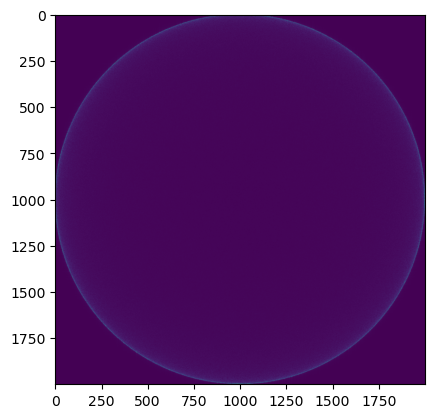

In [41]:
plt.imshow(np.abs(uninverted))

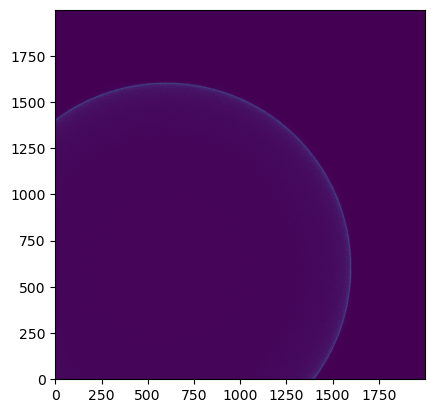

In [42]:
plt.imshow(np.abs(inverted),origin="lower")

In [43]:
window_size = 3  # choose an odd number so the center is clear
half_w = window_size // 2

rows, cols = uninverted.shape

# Pad the frame to handle edges
padded_first = np.pad(uninverted, half_w, mode="constant", constant_values=0)
padded_second = np.pad(inverted, half_w, mode="constant", constant_values=0)

local_corr = np.zeros_like(uninverted)

for i in tqdm(range(rows)):
    for j in range(cols):
        patch1 = np.abs(padded_first[i : i + window_size, j : j + window_size])**2
        patch2 = np.abs(padded_second[i : i + window_size, j : j + window_size])**2
        local_corr[i, j] = np.sum(patch1 * patch2) / (np.sqrt(np.sum(patch1**2) * np.sum(patch2**2)))

  0%|          | 0/2000 [00:00<?, ?it/s]

/tmp/ipykernel_592468/1359274495.py:16: RuntimeWarning: invalid value encountered in scalar divide
  local_corr[i, j] = np.sum(patch1 * patch2) / (np.sqrt(np.sum(patch1**2) * np.sum(patch2**2)))
100%|██████████| 2000/2000 [00:42<00:00, 47.49it/s]


In [44]:
nan_mask = ~np.isnan(local_corr)
rows = np.any(nan_mask, axis=1)
cols = np.any(nan_mask, axis=0)

r0, r1 = np.where(rows)[0][[0, -1]]
c0, c1 = np.where(cols)[0][[0, -1]]
block = local_corr[r0:r1+1, c0:c1+1]

In [45]:
print(c0,c1)
print(r0,r1)

0 1601
0 1601


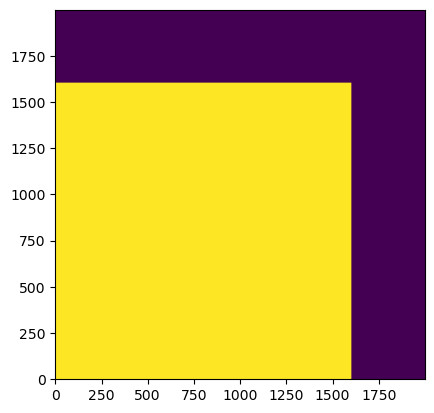

In [46]:
plt.imshow(nan_mask,origin="lower")

In [47]:
Nky, Nkx = uninverted.shape

kx_coords = np.linspace(-1, 1, Nkx)
ky_coords = np.linspace(-1, 1, Nky)
KX, KY = np.meshgrid(kx_coords, ky_coords)
KX_crop = KX[r0:r1+1, c0:c1+1]
KY_crop = KY[r0:r1+1, c0:c1+1]

In [48]:
kx_min, kx_max = KX_crop.min(), KX_crop.max()
ky_min, ky_max = KY_crop.min(), KY_crop.max()
Nx, Ny = 3000, 3000  # or whatever you want

kx = np.linspace(kx_min, kx_max, Nx)
ky = np.linspace(ky_min, ky_max, Ny)
KX_new, KY_new = np.meshgrid(kx, ky)


def f(KX, KY):
    return (
        np.sqrt(1 - ki_x**2 - ki_y**2)
        + np.sqrt(1 - ku_x**2 - ku_y**2)
        - np.sqrt(1 - KX**2 - KY**2)
        - np.sqrt(1 - (2 * c_x - KX) ** 2 - (2 * c_y - KY) ** 2)
    )


F = f(KX_new, KY_new)

/tmp/ipykernel_592468/3626754365.py:14: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - KX**2 - KY**2)
/tmp/ipykernel_592468/3626754365.py:15: RuntimeWarning: invalid value encountered in sqrt
  - np.sqrt(1 - (2 * c_x - KX) ** 2 - (2 * c_y - KY) ** 2)


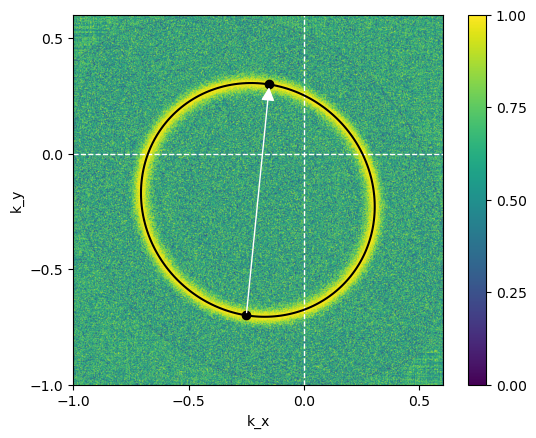

In [49]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

# Base image
im = ax.imshow(
    np.abs(block),
    origin="lower",
    extent=[KX_crop.min(), KX_crop.max(), KY_crop.min(), KY_crop.max()],
    vmin=0,
    vmax=1,
    cmap="viridis",
)
lw = 1.5
ax.contour(
    KX_new,
    KY_new,
    F,
    levels=[0],
    colors="black",
    linewidths=lw,
)

# Overlay contour of mask
# ax.contour(KX_crop, KY_crop, theory_mask.astype(float), levels=[0.5], colors='red', linewidths=0.5)

# Plot ki and ku points
ms = 6
circle_color = "black"
ax.plot(ki_x, ki_y, marker='o', color=circle_color, ms=ms, label='ki')
ax.plot(ku_x, ku_y, marker='o', color=circle_color, ms=ms, label='ki')

cbar = fig.colorbar(im, ax=ax)

cbar.ax.yaxis.set_major_locator(MultipleLocator(0.25))

# Draw arrow from ki → ku
ax.annotate(
    "",
    xy=(ku_x, ku_y),
    xytext=(ki_x, ki_y),
    arrowprops=dict(
        arrowstyle="-|>", color="white", linewidth=1, mutation_scale=20
    ),
    zorder=3,
)
ax.axhline(0, color="white", linestyle="--", linewidth=1,zorder=0)
ax.axvline(0, color="white", linestyle="--", linewidth=1,zorder=0)
ax.set_xlabel("k_x")
ax.set_ylabel("k_y")

ax.set_xlim(np.min(KX_crop), np.max(KX_crop))
ax.set_ylim(np.min(KY_crop), np.max(KY_crop))
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
plt.savefig("pseudo_ring.svg",format="svg")

plt.show()

In [50]:
assert False

AssertionError: 

In [ ]:
import numpy as np

def is_circle(mask, tol=1.0):
    # Get coordinates of True pixels
    ys, xs = np.where(mask)
    
    if len(xs) < 3:
        return False  # not enough points
    
    # Estimate center (centroid)
    cx = np.mean(xs)
    cy = np.mean(ys)
    
    # Distances from center
    dists = np.sqrt((xs - cx)**2 + (ys - cy)**2)
    
    # Check variation in radius
    return np.std(dists) < tol
plt.spy(theory_mask)

NameError: name 'theory_mask' is not defined

In [ ]:
assert False

AssertionError: 

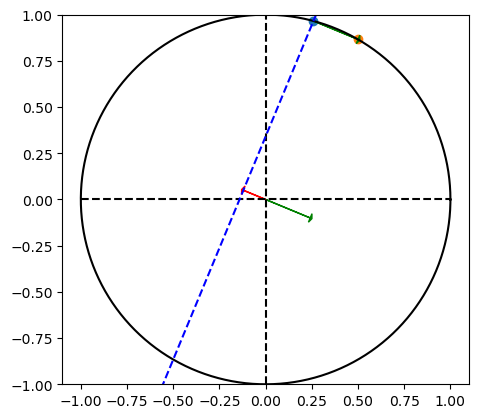

In [ ]:
# Example plot
theta1 = np.pi/180 * 15
theta2 = np.pi/180 * 30
c1 = np.cos(theta1)
c2 = np.cos(theta2)
s1 = np.sin(theta1)
s2 = np.sin(theta2)
c = np.cos(theta1 - theta2)

t = np.linspace(0,2*np.pi,1000)
x = np.cos(t)
y = np.sin(t)

ki = (s1,c1)
ku = (s2,c2)
n = np.array(ku) - np.array(ki)
dx = n[0]
dy = n[1]


fig, ax = plt.subplots()
ax.plot(x, y, color="black")

ax.plot([-1, 1], [0, 0], linestyle="--", color="black")
ax.plot([0, 0], [-1, 1], linestyle="--", color="black")
ax.set_aspect("equal")


ax.scatter(*ki)
ax.scatter(*ku)
ax.arrow(ki[0], ki[1], dx, dy, head_width=0.05, head_length=0.01, fc='green', ec='green')
ax.arrow(0, 0, dx, dy, head_width=0.05, head_length=0.01, fc='green', ec='green')
ax.arrow(0, 0, -dx/2, -dy/2, head_width=0.05, head_length=0.01, fc='red', ec='red')

# Plot the line corresponding to plane intersection
y_line = np.linspace(-1, 1, 100)
# Solve for z in terms of y
z_line = (c - 1 - y_line * (s2-s1)) / (c2-c1)

ax.set_ylim(-1,1)
ax.plot(y_line, z_line, linestyle="--", color="blue")

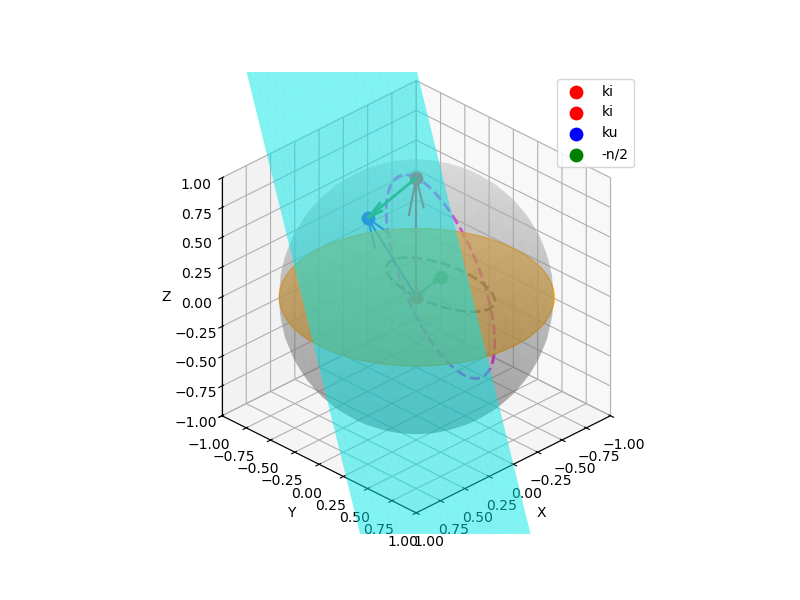

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Sphere radius
k = 1.0

# Spherical coordinates for ki and kj
theta1, phi1 = 0, 0   # ki at north pole
theta2, phi2 = np.pi/6, 0   # kj 60 deg from z

# Spherical -> Cartesian
def spherical_to_cartesian(k, theta, phi):
    x = k * np.sin(theta) * np.cos(phi)
    y = k * np.sin(theta) * np.sin(phi)
    z = k * np.cos(theta)
    return np.array([x, y, z])

ki = spherical_to_cartesian(k, theta1, phi1)
ku = spherical_to_cartesian(k, theta2, phi2)

# Vector n and midpoint
n = ku - ki
midpoint = -n/2

# Plane equation function: n_x x + n_y y + n_z z = -|n|^2 / 2
def plane_z(x, y, n):
    return (0.5 * np.dot(n, n) - n[0]*x - n[1]*y) / n[2]

# Plane grid
grid_size = 30
grid_range = np.linspace(-k, k, grid_size)
X, Y = np.meshgrid(grid_range, grid_range)
Z = plane_z(X, Y, n)

# Plot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d', proj_type='ortho')

# Sphere
u, v = np.mgrid[0:2*np.pi:50j, 0:np.pi:25j]
xs = k*np.cos(u)*np.sin(v)
ys = k*np.sin(u)*np.sin(v)
zs = k*np.cos(v)
ax.plot_surface(xs, ys, zs, color='lightgray', alpha=0.3)

# Points
ax.scatter(*ki, color='red', s=80, label='ki')
ax.scatter(ki[0], ki[1],0 , color='red', s=80, label='ki')

ax.scatter(*ku, color='blue', s=80, label='ku')
ax.scatter(*midpoint, color='green', s=80, label='-n/2')

# Arrows from origin
ax.quiver(0,0,0,*ki, color='red', length=1, normalize=True)
ax.quiver(0,0,0,*ku, color='blue', length=1, normalize=True)
ax.quiver(0,0,0,*midpoint, color='green', length=1, normalize=False)

# Arrow from ki to kj
arrow_vec = ku - ki
ax.quiver(*ki, *arrow_vec, color='green', length=1, normalize=False, linewidth=2)

# Plane
ax.plot_surface(X, Y, Z, color='cyan', alpha=0.5)

# Aspect and limits
ax.set_box_aspect([1,1,1])
ax.set_xlim([-k,k])
ax.set_ylim([-k,k])
ax.set_zlim([-k,k])

# Fixed elevation, interactive azimuth
elev_fixed = 30
ax.view_init(elev=elev_fixed, azim=45)

def on_mouse_drag(event):
    if event.button != 1:
        return
    az = ax.azim
    ax.view_init(elev=elev_fixed, azim=az)
    fig.canvas.draw_idle()

fig.canvas.mpl_connect('motion_notify_event', on_mouse_drag)

# ---------------------------------
# Plane
# Filled XY slice (z=0)

# Generate points around the circle
theta = np.linspace(0, 2*np.pi, 200)
x_circle = k * np.cos(theta)
y_circle = k * np.sin(theta)
z_circle = np.zeros_like(theta)

# Combine into a single array of vertices for the polygon
verts = [list(zip(x_circle, y_circle, z_circle))]

# Create a filled 3D polygon
disk = Poly3DCollection(verts, color='orange', alpha=0.7)
ax.add_collection3d(disk)
# -------------------------------------------------------
# Compute plane-sphere intersection circle
c = -n / 2  # center of circle along plane normal
r_circle = np.sqrt(k**2 - np.dot(c, c))  # radius of circle

# Orthonormal basis in the plane
# Pick a vector not parallel to n
tmp = np.array([1,0,0]) if abs(n[0]) < 0.9 else np.array([0,1,0])
u = tmp - np.dot(tmp, n)/np.dot(n,n)*n
u /= np.linalg.norm(u)
v = np.cross(n, u)

# Parametrize circle
t = np.linspace(0, 2*np.pi, 300)
circle = c[:, None] + r_circle*(u[:, None]*np.cos(t) + v[:, None]*np.sin(t))

# Plot dashed circle
ax.plot(circle[0], circle[1], circle[2], linestyle='--', color='magenta', linewidth=2)


# --------------------------------
# Projection
# Project the magenta plane-sphere intersection circle onto the xy-plane
x_proj = circle[0]   # x-coordinates
y_proj = circle[1]   # y-coordinates
z_proj = np.zeros_like(x_proj)  # z = 0 for projection

# Plot the projection as a dashed black line
ax.plot(x_proj, y_proj, z_proj, linestyle='--', color='black', linewidth=2, alpha=0.8)


ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend()
plt.show()

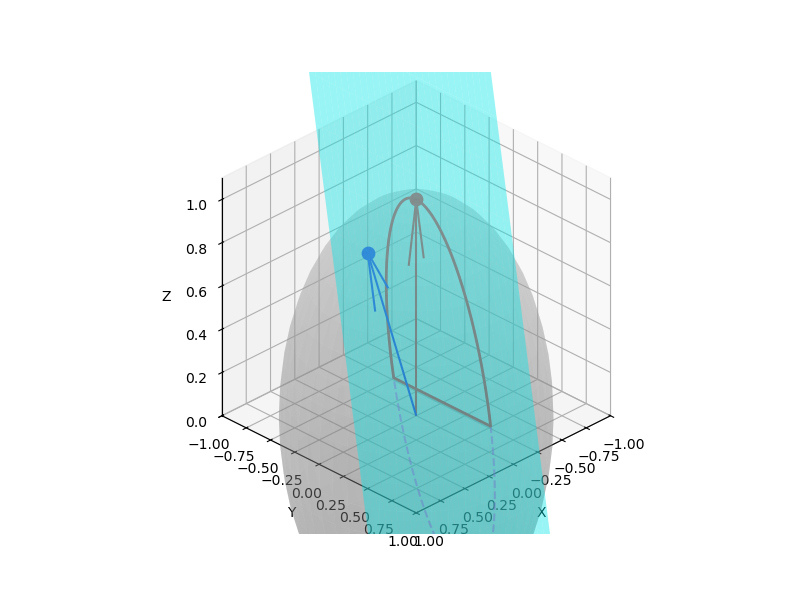

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

# Sphere radius
k = 1.0

# Spherical -> Cartesian
def spherical_to_cartesian(k, theta, phi):
    x = k * np.sin(theta) * np.cos(phi)
    y = k * np.sin(theta) * np.sin(phi)
    z = k * np.cos(theta)
    return np.array([x, y, z])

# Example vectors
theta_i, phi_i = 0, 0        # ki at north pole
theta_u, phi_u = np.pi/6, 0  # ku slightly away from pole

ki = spherical_to_cartesian(k, theta_i, phi_i)
ku = spherical_to_cartesian(k, theta_u, phi_u)

# n vector
n = ku - ki

# Plane equation: kj dot n = -0.5 |n|^2
def plane_z(x, y, n):
    return (-0.5*np.dot(n,n) - n[0]*x - n[1]*y) / n[2]

# Plane grid
grid_size = 30
grid_range = np.linspace(-k, k, grid_size)
X, Y = np.meshgrid(grid_range, grid_range)
Z = plane_z(X, Y, n)

# Sphere mesh
u, v = np.mgrid[0:2*np.pi:50j, 0:np.pi:25j]
xs = k*np.cos(u)*np.sin(v)
ys = k*np.sin(u)*np.sin(v)
zs = k*np.cos(v)

# Plane-sphere intersection circle
c = -n/2
r_circle = np.sqrt(k**2 - np.dot(c,c))
tmp = np.array([1,0,0]) if abs(n[0]) < 0.9 else np.array([0,1,0])
u_vec = tmp - np.dot(tmp,n)/np.dot(n,n)*n
u_vec /= np.linalg.norm(u_vec)
v_vec = np.cross(n, u_vec)
t = np.linspace(0, 2*np.pi, 300)
circle = c[:, None] + r_circle*(u_vec[:, None]*np.cos(t) + v_vec[:, None]*np.sin(t))

# Mask for upper hemisphere (z>0)
mask_upper = circle[2] > 0
circle_upper = circle[:, mask_upper]

# Plot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d', proj_type='ortho')

# Sphere
ax.plot_surface(xs, ys, zs, color='lightgray', alpha=0.3)

# Plane (transparent)
ax.plot_surface(X, Y, Z, color='cyan', alpha=0.4)

# Full plane-sphere circle
ax.plot(circle[0], circle[1], circle[2], linestyle='--', color='magenta', alpha=0.5)

# Upper hemisphere arc only
ax.plot(circle_upper[0], circle_upper[1], circle_upper[2], linestyle='-', color='red', linewidth=2)

# Vectors
ax.quiver(0,0,0,*ki, color='red', length=1, normalize=True)
ax.quiver(0,0,0,*ku, color='blue', length=1, normalize=True)

ax.scatter(*ki, color='red', s=80)
ax.scatter(*ku, color='blue', s=80)

# Aspect and limits
ax.set_box_aspect([1,1,1])
ax.set_xlim([-k,k])
ax.set_ylim([-k,k])
ax.set_zlim([0,k*1.1])  # show upper hemisphere only

# Fixed elevation, interactive azimuth
elev_fixed = 30
ax.view_init(elev=elev_fixed, azim=45)

def on_mouse_drag(event):
    if event.button != 1:
        return
    az = ax.azim
    ax.view_init(elev=elev_fixed, azim=az)
    fig.canvas.draw_idle()

fig.canvas.mpl_connect('motion_notify_event', on_mouse_drag)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

In [ ]:
assert False

AssertionError: 

In [ ]:
import matplotlib.animation as animation
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# Normalized k-space limits
kx_min, kx_max = -1, 1
ky_min, ky_max = -1, 1

# Keep your test_max logic exactly
ratio_lower = 0.35
ratio_upper = 0.40
low_index = int(measurement_number_kx * ratio_lower)
high_index = int(measurement_number_kx * ratio_upper)

test_max = np.max(
    [
        np.max(
            np.abs(scattered_fields_plot[i])[low_index:high_index, low_index:high_index]
        )
        for i in wavevector_indices
    ]
)


NameError: name 'wavevector_indices' is not defined

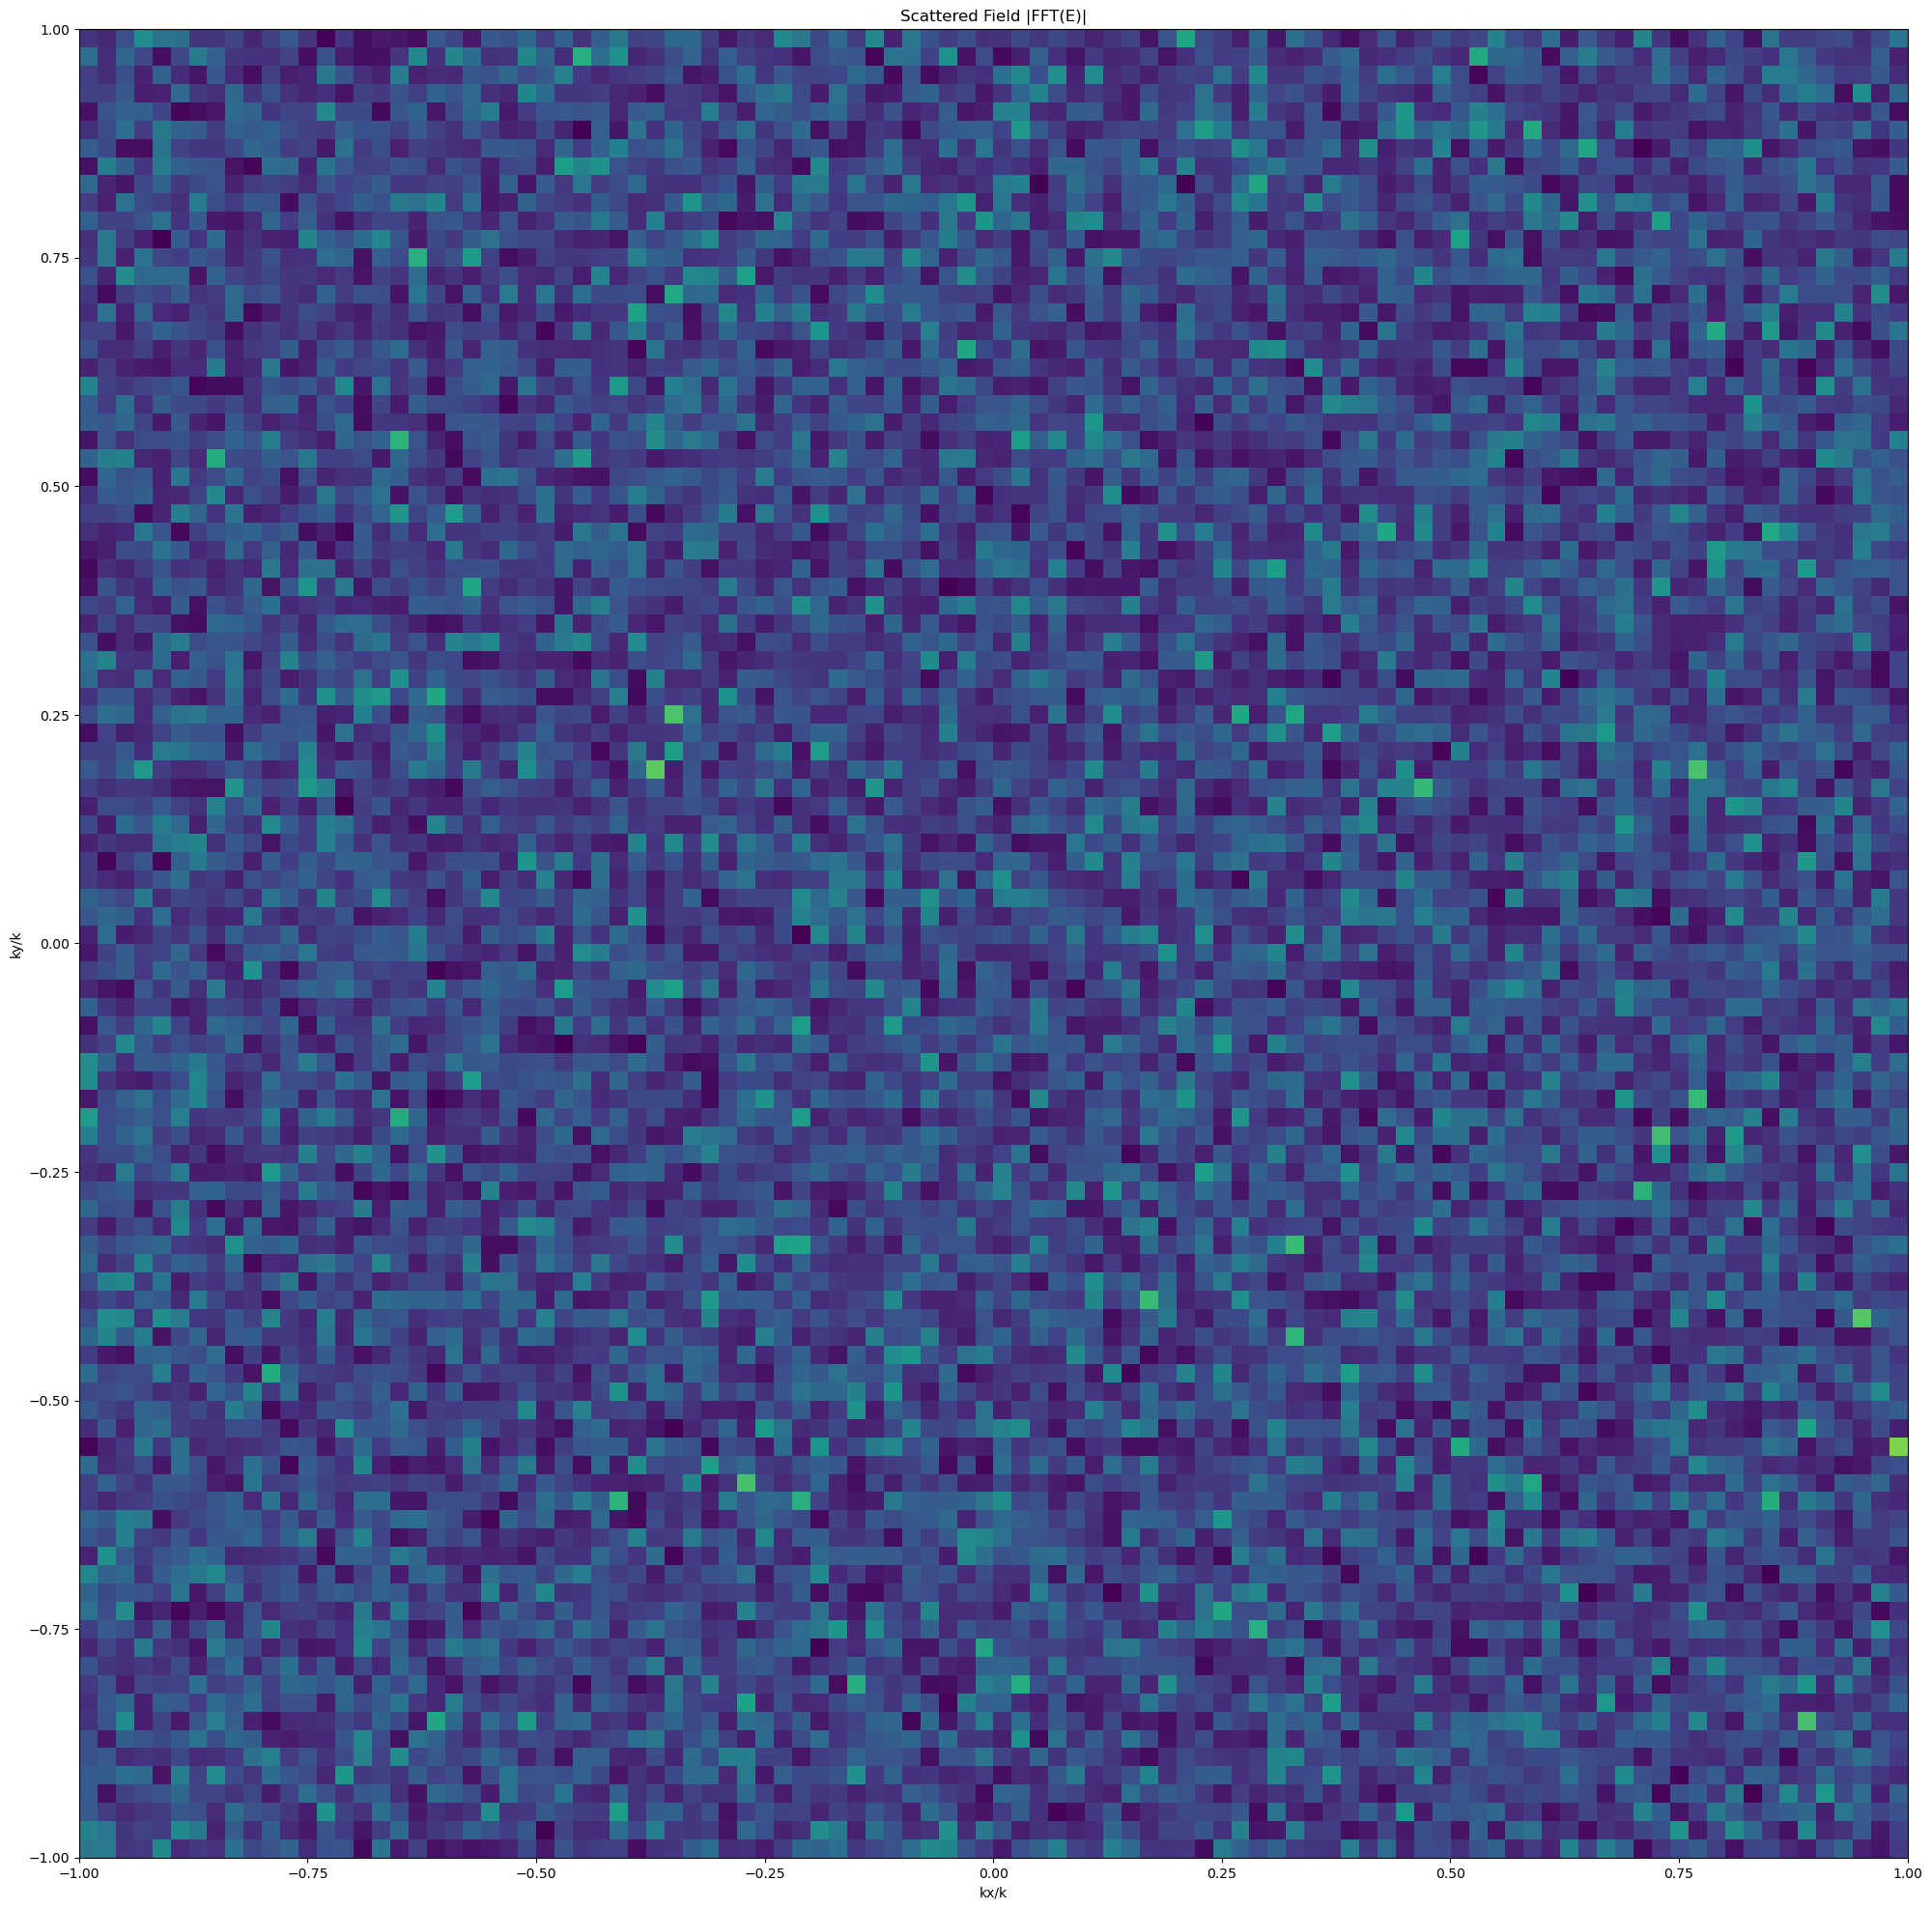

In [ ]:
import matplotlib.animation as animation
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# Normalized k-space limits
kx_min, kx_max = -1, 1
ky_min, ky_max = -1, 1

# Keep your test_max logic exactly
ratio_lower = 0.35
ratio_upper = 0.40
low_index = int(measurement_number_kx * ratio_lower)
high_index = int(measurement_number_kx * ratio_upper)

test_max = np.max(
    [
        np.max(
            np.abs(scattered_fields_plot[i])[low_index:high_index, low_index:high_index]
        )
        for i in wavevector_indices
    ]
)

# Create figure and axis
fig, ax = plt.subplots(figsize=(20, 20))  # larger figure for "massive" view

sca_k_im = ax.imshow(
    np.abs(scattered_fields_plot[0])[window,window],
    extent=[kx_min, kx_max, ky_min, ky_max],
    origin="lower",
    cmap="viridis",
    vmax=test_max,  # keep your test_max
)
ax.set_title("Scattered Field |FFT(E)|")
ax.set_xlabel("kx/k")
ax.set_ylabel("ky/k")
plt.tight_layout()

# Update function
def update(frame):
    sca_k_im.set_data(np.abs(scattered_fields_plot[frame][window,window]))
    return sca_k_im,

# Create animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(wavevector_indices),
    interval=200,  # ms per frame
    blit=True,
)

# To display in Jupyter
# from IPython.display import HTML
# HTML(ani.to_jshtml())

# Or save to file
fps = 60
ani.save(f"scattered_k_animation_fps={fps}.mp4", fps=fps, dpi=100)

In [ ]:
def get_mask(
    first_index: int,
    second_index: int,
    sp: plane_wave.SimulationParameters,
    tol: float = 5e-4,
):
    xp = cp if sp.use_cupy else np

    xm = xp.linspace(-1.0, 1.0, len(sp.measurement_x_points))
    ym = xp.linspace(-1.0, 1.0, len(sp.measurement_y_points))
    Xm, Ym = xp.meshgrid(xm, ym, indexing="xy")

    kx1 = kx[first_index]
    ky1 = ky[first_index]
    kx2 = kx[second_index]
    ky2 = ky[second_index]

    dkx = kx2 - kx1
    dky = ky2 - ky1

    r1 = 1 - Xm**2 - Ym**2
    r2 = 1 - (Xm + dkx) ** 2 - (Ym + dky) ** 2

    domain = (r1 >= 0) & (r2 >= 0)

    F = (
        xp.sqrt(1 - kx1**2 - ky1**2)
        - xp.sqrt(1 - kx2**2 - ky2**2)
        - xp.sqrt(1 - Xm**2 - Ym**2)
        + xp.sqrt(1 - (Xm + dkx) ** 2 - (Ym + dky) ** 2)
    )
    mask = domain & (xp.abs(F) < tol)
    return mask

def mask_incident_peak(kx_grid, ky_grid, kx0, ky0, radius=0.02):
    """
    Create a boolean mask that is True everywhere except inside a
    circular region around the incident peak in k-space.
    """
    return np.sqrt((kx_grid - kx0) ** 2 + (ky_grid - ky0) ** 2) > radius

In [ ]:
%matplotlib inline
from matplotlib.colors import ListedColormap
num_frames = len(incident_fields_plot)

# Compute global color limits (as you already did)
inc_all_min = min(np.min(np.abs(frame)) for frame in incident_fields_plot)
inc_all_max = max(np.max(np.abs(frame)) for frame in incident_fields_plot)
sca_all_min = min(np.min(np.abs(frame)) for frame in scattered_fields_plot)
sca_all_max = max(np.max(np.abs(frame)) for frame in scattered_fields_plot)

tol = 1e-4

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
# title = fig.suptitle(f"t = {t_values[0]:.5f}")

inc_im = ax[0].imshow(
    np.abs(incident_fields_plot[0]),
    cmap="viridis",
    origin="lower",
    extent=[-1, 1, -1, 1],
    vmin=inc_all_min,
    vmax=inc_all_max,
)
sca_im = ax[1].imshow(
    np.abs(scattered_fields_plot[0]),
    cmap="viridis",
    origin="lower",
    extent=[-1, 1, -1, 1],
    vmin=sca_all_min,
    vmax=sca_all_max,
)
white_cmap = ListedColormap([[1, 1, 1]])  # RGB for white
mask_initial = get_mask(0, 1, sp, tol).get()
mask_im = ax[1].imshow(
    mask_initial, origin="lower", extent=[-1, 1, -1, 1], cmap=white_cmap, alpha=0.2
)

kx0 = incident_wavevectors[0, 0]  # kx at first frame
ky0 = incident_wavevectors[0, 1]  # ky at first frame
# red_spot, = ax[1].plot(kx0, ky0, "ro", markersize=6)  # red circle

def update(idx):
    inc_im.set_data(np.abs(incident_fields_plot[idx]))
    sca_im.set_data(np.abs(scattered_fields_plot[idx]))
    # title.set_text(f"t = {t_values[idx]:.5f}")

    second_idx = min(idx + 1, num_frames - 1)
    mask_data = get_mask(idx, second_idx, sp, tol).get()
    masked_overlay = np.ma.masked_where(~mask_data, mask_data)
    mask_im.set_data(masked_overlay)

    # red_spot.set_data(incident_wavevectors[idx, 0], incident_wavevectors[idx, 1])
    return inc_im, sca_im, mask_im


ani = animation.FuncAnimation(
    fig,
    update,
    frames=num_frames,
    blit=True,
)

# Save at 60 fps
ani.save("speckles_30fps.mp4", fps=10, dpi=200)

In [ ]:
assert False

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import Play, jslink, HBox, VBox, IntSlider, Label
from IPython.display import display
import matplotlib

# Assume incident_fields_plot, scattered_fields_plot, t_values, sp, get_mask are defined
num_frames = len(incident_fields_plot)

# Compute global color limits
inc_all_min = min(np.min(np.abs(frame)) for frame in incident_fields_plot)
inc_all_max = max(np.max(np.abs(frame)) for frame in incident_fields_plot)
sca_all_min = min(np.min(np.abs(frame)) for frame in scattered_fields_plot)
sca_all_max = max(np.max(np.abs(frame)) for frame in scattered_fields_plot)

# Create figure and axes
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
title = fig.suptitle(f"t = {t_values[0]:.5f}")

inc_im = ax[0].imshow(
    np.abs(incident_fields_plot[0]),
    cmap="viridis",
    origin="lower",
    extent=[-1, 1, -1, 1],
    vmin=inc_all_min,
    vmax=inc_all_max,
)
sca_im = ax[1].imshow(
    np.abs(scattered_fields_plot[0]),
    cmap="viridis",
    origin="lower",
    extent=[-1, 1, -1, 1],
    vmin=sca_all_min,
    vmax=sca_all_max,
)

# Initial mask overlay
mask_initial = get_mask(0, 1, sp).get()
masked_overlay = np.ma.masked_where(~mask_initial, mask_initial)
mask_im = ax[1].imshow(
    masked_overlay,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="Greys",
    alpha=0.3,
)

for a in ax:
    a.set_aspect("equal")

# Create a Play widget
play = Play(
    value=0,
    min=0,
    max=num_frames-1,
    step=1,
    interval=1000,
    description="Play",
    auto_play=False  # <-- this prevents auto-start
)


# Create a slider linked to the Play widget
slider = IntSlider(min=0, max=num_frames-1, step=1, value=0)
jslink((play, 'value'), (slider, 'value'))

# Update function
def update_frame(idx):
    inc_im.set_data(np.abs(incident_fields_plot[idx]))
    sca_im.set_data(np.abs(scattered_fields_plot[idx]))
    title.set_text(f"t = {t_values[idx]:.5f}")

    second_idx = min(idx + 1, num_frames - 1)
    mask_data = get_mask(idx, second_idx, sp).get()
    masked_overlay = np.ma.masked_where(~mask_data, mask_data)
    mask_im.set_data(masked_overlay)

    fig.canvas.draw_idle()

# Link slider to update function
slider.observe(lambda change: update_frame(change['new']), names='value')

# Display slider and play controls
display(VBox([play, slider]))

In [ ]:
mask_initial = get_mask(0, 1, sp)


In [ ]:
assert False

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

num_frames = len(speckles_plot)

# Compute global color limits (as you already did)
all_min = min(np.min(np.abs(frame)) for frame in speckles_plot)
all_max = max(np.max(np.abs(frame)) for frame in speckles_plot)

fig, ax = plt.subplots()

im = ax.imshow(
    np.abs(speckles_plot[0]),
    cmap="viridis",
    origin="lower",
    vmin=all_min,
    vmax=all_max,
)
fig.colorbar(im, ax=ax)

def update(idx):
    im.set_data(np.abs(speckles_plot[idx]))
    ax.set_title(f"t = {t_values[idx]:.5f}")
    return [im]

ani = animation.FuncAnimation(
    fig,
    update,
    frames=num_frames,
    blit=True,
)

# Save at 60 fps
ani.save("speckles_60fps.mp4", fps=30, dpi=200)

In [ ]:
assert False

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import Play, IntSlider, jslink, VBox
from IPython.display import display


# speckles_plot = speckles_np

# speckles = list of 2D arrays
num_frames = len(speckles_plot)
My, Mx = number_x, number_y

# Create figure

frame = speckles_plot[0]

all_min = min(np.min(np.abs(frame)) for frame in speckles_plot)
all_max = max(np.max(np.abs(frame)) for frame in speckles_plot)



fig, ax = plt.subplots()
im = ax.imshow(np.abs(frame), cmap='viridis', origin='lower',
               vmin=all_min, vmax=all_max)
ax.set_title(f"t = {t_values[0]}")
fig.colorbar(im, ax=ax)

# Create ipywidgets slider and play
slider = IntSlider(min=0, max=num_frames-1, step=1, value=0, description='Frame')
play = Play(min=0, max=num_frames-1, step=1, interval=400, description="Play", loop=True)

# Link play to slider
jslink((play, 'value'), (slider, 'value'))

# Update function
def update_frame(idx):


    frame = speckles_plot[idx]

    # frame = speckles_np[idx]
    im.set_data(np.abs(frame))
    ax.set_title(f"t = {t_values[idx]:.5f}")
    fig.canvas.draw_idle()

# Connect slider to update
slider.observe(lambda change: update_frame(change['new']), names='value')

# Display widgets
display(VBox([play, slider]))


In [ ]:

kspace_one = czt2(
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    Nx=number_x,
    Nk=number_x,
    input=speckles[0],
    kscale=sp.wavenumber,
)
kspace_two = czt2(
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    Nx=number_x,
    Nk=number_x,
    input=speckles[1],
    kscale=sp.wavenumber,
)


In [ ]:
%matplotlib inline

fig, ax = plt.subplots()
ax.pcolor(np.abs(kspace_one.get()))
ax.set_aspect("equal")
fig, ax = plt.subplots()
ax.pcolor(np.abs(kspace_two.get()))
ax.set_aspect("equal")


In [ ]:
def get_rolled_correlations(
    array: np.ndarray | cp.ndarray,
    ref: np.ndarray | cp.ndarray,
    rolls: list[int],
) -> list[np.float128]:
    xp = cp.get_array_module(array)
    output = []
    for roll in rolls:
        rolled = xp.roll(array, roll, axis=1)
        prod = rolled * ref.conj()
        output.append(xp.sum(prod))
    return output

In [ ]:
# rolls = range(-10,10)

# field = speckles[0]
# ref = speckles[1]

# rolled_correlations = get_rolled_correlations(field, ref, rolls)
# rolled_correlations = [np.abs(t.get()) for t in rolled_correlations]
# roll = rolls[np.argmax(rolled_correlations)]
# print(roll)
# rolled_field = xp.roll(field, 0, axis=1)

In [ ]:
def pad_with_zeros(array, padsize = 100):
    """
    Pad a 2D CuPy array with zeros on all sides.

    Parameters
    ----------
    array : cp.ndarray
        Input 2D array.
    padsize : int
        Number of rows/columns of zeros to add on each side.

    Returns
    -------
    cp.ndarray
        Padded array of shape (H + 2*padsize, W + 2*padsize)
    """
    H, W = array.shape
    padded = cp.zeros((H + 2*padsize, W + 2*padsize), dtype=array.dtype)
    padded[padsize:padsize+H, padsize:padsize+W] = array
    return padded


In [ ]:
# corr = (field*rolled_field.conj()).get()
# denom_one = (field*field.conj()).get()
# denom_two = (rolled_field*rolled_field.conj()).get()
# final = np.abs(corr / np.sqrt(denom_one * denom_two))


# fig, ax = plt.subplots()
# im = ax.imshow(final.real)
# fig.colorbar(im, ax=ax)

In [ ]:
num_realizations = 1
num_realizations = 15_000
rolls = range(-10, 10)
padsize = 10

x_min = -10 * sp.wavelength
x_max = 10 * sp.wavelength
y_min = -10 * sp.wavelength
y_max = 10 * sp.wavelength

top = xp.zeros(
    (number_x + 2 * padsize, number_y + 2 * padsize), dtype=xp.float64
)
bottom_one = xp.zeros(
    (number_x + 2 * padsize, number_y + 2 * padsize), dtype=xp.float64
)
bottom_two = xp.zeros(
    (number_x + 2 * padsize, number_y + 2 * padsize), dtype=xp.float64
)

for realization in tqdm(range(num_realizations)):

    # Generate random particles
    x, y, z = plane_wave.get_particle_locations(sp, seed=False)

    # Get the speckle patterns for each wavevector
    speckles = []
    for incident_wavevector in incident_wavevectors[[0, 1]]:
        incident_fields = plane_wave.plane_wave(
            x, y, z, incident_wavevector, sp
        )
        scattered_field = plane_wave.get_scattered_fields(
            x, y, z, incident_fields, sp
        )
        speckles.append(scattered_field)

    # speckles_np = [s.get() for s in speckles]

    # Calculate correlations for the speckles

    field = pad_with_zeros(
        czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=number_x,
            Nk=number_x,
            input=speckles[1],
            kscale=sp.wavenumber,
        ),
        padsize,
    )
    ref = pad_with_zeros(
        czt2(
            x_min=x_min,
            x_max=x_max,
            y_min=y_min,
            y_max=y_max,
            Nx=number_x,
            Nk=number_x,
            input=speckles[0],
            kscale=sp.wavenumber,
        ),
        padsize,
    )

    # field = speckles[1]
    # ref = speckles[0]

    rolled_correlations = get_rolled_correlations(field, ref, rolls)
    rolled_correlations = xp.array([xp.abs(t) for t in rolled_correlations])
    roll = rolls[xp.argmax(rolled_correlations).item()]
    rolled_field = xp.roll(field, roll, axis=1)
    top = top + (field * rolled_field.conj())
    bottom_one = bottom_one + (field * field.conj())
    bottom_two = bottom_two + (rolled_field * rolled_field.conj())

final = xp.abs(top / xp.sqrt(bottom_one * bottom_two))

In [ ]:
plt.imshow(np.abs(final.get()), vmin=0.91, vmax=1.0)
plt.colorbar()

In [ ]:
top[20,20]

In [ ]:
bottom_one[20,20]

In [ ]:
bottom_two[20,20]

In [ ]:
plt.imshow(np.abs(ref.get()))
plt.colorbar()

In [ ]:
size = len(scattered_fields_plot[0])
center = int(size//2)
diff = 50
window = slice(center - diff, center + diff)
wavevector_indices = range(len(scattered_fields_plot))

KX, KY = np.meshgrid(np.linspace(-1,1,size), np.linspace(-1,1,size))
KX = KX[window,window]
KY = KY[window,window]
print(KY.shape)

# Normalized k-space limits
kx_min, kx_max = -1, 1
ky_min, ky_max = -1, 1

# Keep your test_max logic exactly
ratio_lower = 0.35
ratio_upper = 0.40
low_index = int(measurement_number_kx * ratio_lower)
high_index = int(measurement_number_kx * ratio_upper)

test_max = np.max(
    [
        np.max(
            np.abs(scattered_fields_plot[i])[low_index:high_index, low_index:high_index]
        )
        for i in wavevector_indices
    ]
)